In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Load the real-world Iris dataset
iris = load_iris()
X = iris.data 
y = iris.target 

# Create a DataFrame
df = pd.DataFrame(X, columns=iris.feature_names)
df['species'] = y  # 0: Setosa, 1: Versicolor, 2: Virginica

print("Dataset Overview (First 5 rows):")
display(df.head())

print("\nBasic Statistical Summary (Pre-EDA):")
display(df.describe())

Dataset Overview (First 5 rows):


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0



Basic Statistical Summary (Pre-EDA):


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


Correlation Matrix:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000000,-0.117570,0.871754,0.817941
sepal width (cm),-0.117570,1.000000,-0.428440,-0.366126
petal length (cm),0.871754,-0.428440,1.000000,0.962865
petal width (cm),0.817941,-0.366126,0.962865,1.000000


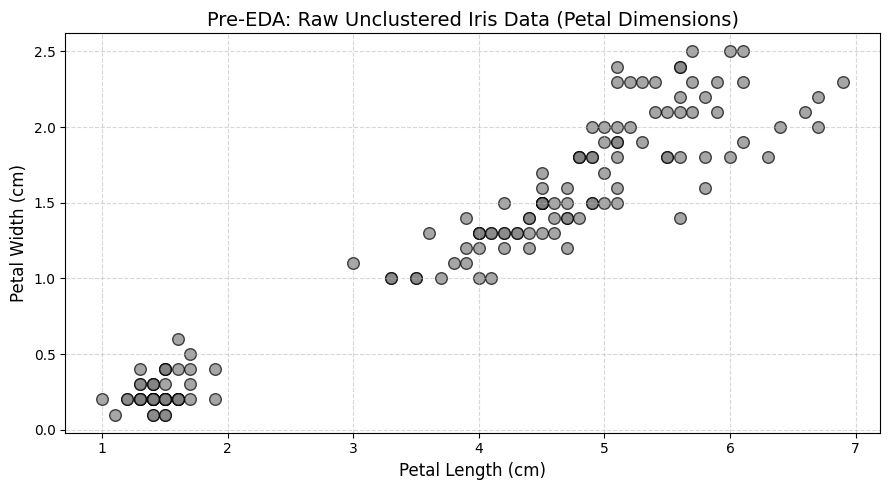

In [2]:
# Check feature correlation
print("Correlation Matrix:")
display(df.iloc[:, :-1].corr())

# Pre-EDA Visualization: Raw Unclustered Data
plt.figure(figsize=(9, 5))
plt.scatter(
    df['petal length (cm)'], 
    df['petal width (cm)'], 
    c='gray', 
    edgecolors='k', 
    s=70, 
    alpha=0.7
)
plt.title('Pre-EDA: Raw Unclustered Iris Data (Petal Dimensions)', fontsize=14)
plt.xlabel('Petal Length (cm)', fontsize=12)
plt.ylabel('Petal Width (cm)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [3]:
# Select features for clustering
X_subset = df[['petal length (cm)', 'petal width (cm)']].values

# Scale features (Mean = 0, Variance = 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_subset)

# Fit K-Means
kmeans = KMeans(n_clusters=3, init='k-means++', random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

# Retrieve centroids in original scale
centroids_original = scaler.inverse_transform(kmeans.cluster_centers_)

print("K-Means successfully applied! Cluster counts:")
print(df['Cluster'].value_counts())

K-Means successfully applied! Cluster counts:
Cluster
2    52
1    50
0    48
Name: count, dtype: int64


In [6]:
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from scipy.stats import mode

# 1. Unsupervised Silhouette Score (Ranges from -1 to 1, higher is better)
# Measures how similar an object is to its own cluster compared to other clusters.
sil_score = silhouette_score(X_scaled, df['Cluster'])
print(f"1. Silhouette Score: {sil_score:.4f} (Close to 1.0 indicates dense, well-separated clusters)")

# 2. External Metrics (Comparing against true species labels 'y')
# Adjusted Rand Index (ARI): 1.0 means a perfect match with true labels.
ari = adjusted_rand_score(y, df['Cluster'])
print(f"2. Adjusted Rand Index (ARI): {ari:.4f}")

# Normalized Mutual Information (NMI): Measures agreement between clusters and true classes.
nmi = normalized_mutual_info_score(y, df['Cluster'])
print(f"3. Normalized Mutual Information (NMI): {nmi:.4f}")

# 3. Calculating Mapped Classification Accuracy
# Since K-Means cluster IDs (0, 1, 2) might not match true species IDs (0, 1, 2) directly,
# we map each cluster to the most frequent true label inside it.
labels = np.zeros_like(df['Cluster'])
for i in range(3):
    mask = (df['Cluster'] == i)
    # Find the most common true label in this cluster
    labels[mask] = mode(y[mask], keepdims=True).mode[0]

# Calculate accuracy percentage
accuracy = np.mean(labels == y) * 100
print(f"4. Mapped Classification Accuracy: {accuracy:.2f}%")

1. Silhouette Score: 0.6741 (Close to 1.0 indicates dense, well-separated clusters)
2. Adjusted Rand Index (ARI): 0.8857
3. Normalized Mutual Information (NMI): 0.8642
4. Mapped Classification Accuracy: 96.00%


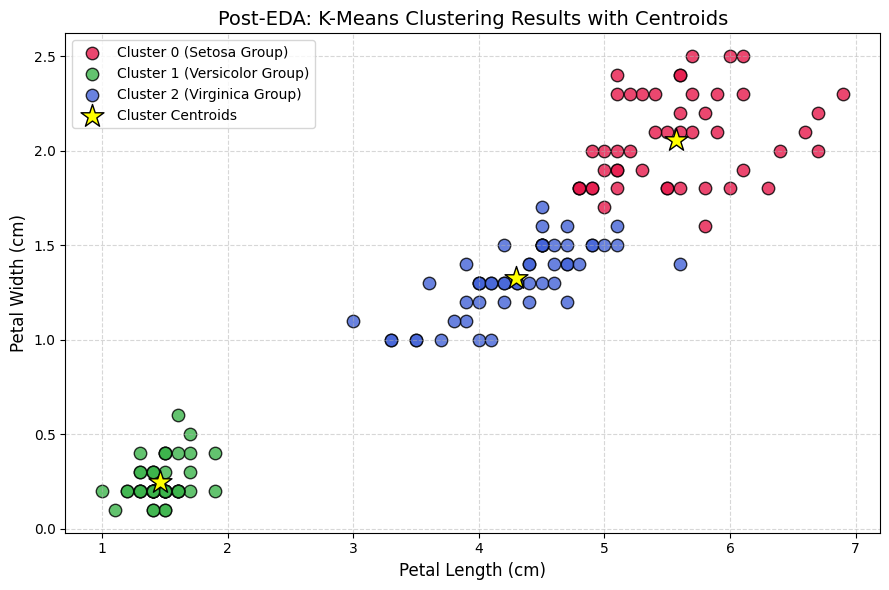

In [4]:
plt.figure(figsize=(9, 6))

colors = ['#e6194b', '#3cb44b', '#4363d8']
cluster_labels = ['Cluster 0 (Setosa Group)', 'Cluster 1 (Versicolor Group)', 'Cluster 2 (Virginica Group)']

# Plot each discovered cluster
for i in range(3):
    cluster_data = X_subset[df['Cluster'] == i]
    plt.scatter(
        cluster_data[:, 0],
        cluster_data[:, 1],
        s=80,
        c=colors[i],
        label=cluster_labels[i],
        alpha=0.8,
        edgecolors='k'
    )

# Plot Centroids as yellow stars
plt.scatter(
    centroids_original[:, 0],
    centroids_original[:, 1],
    s=300,
    c='yellow',
    marker='*',
    edgecolors='black',
    label='Cluster Centroids'
)

plt.title('Post-EDA: K-Means Clustering Results with Centroids', fontsize=14)
plt.xlabel('Petal Length (cm)', fontsize=12)
plt.ylabel('Petal Width (cm)', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

New Flower Sample: Petal Length = 4.5 cm, Petal Width = 1.4 cm
Assigned Cluster: Cluster 2
Distances to all centroids (scaled): [1.05535365 2.29979001 0.15221763]
Nearest Centroid Index: 2


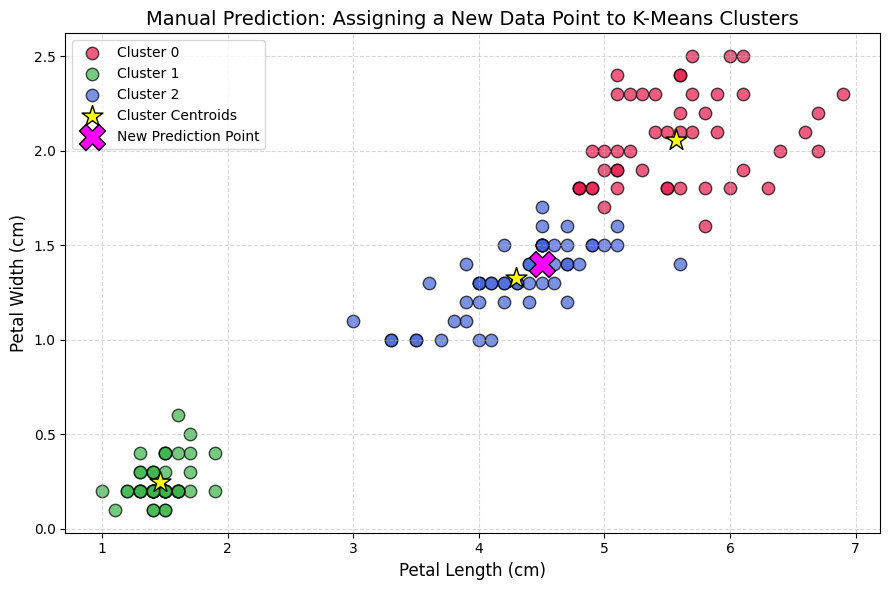

In [5]:
# 1. Define a new, unseen flower sample [petal length, petal width]
new_flower = np.array([[4.5, 1.4]])

# 2. Scale the new data point using the SAME fitted scaler from earlier
new_flower_scaled = scaler.transform(new_flower)

# 3. Predict the cluster using the trained K-Means model
predicted_cluster = kmeans.predict(new_flower_scaled)[0]

# 4. Calculate Euclidean distances from the new point to all centroids
# (K-Means assigns the point to the centroid with the minimum distance)
distances = np.linalg.norm(kmeans.cluster_centers_ - new_flower_scaled, axis=1)
nearest_centroid_idx = np.argmin(distances)

print(f"New Flower Sample: Petal Length = 4.5 cm, Petal Width = 1.4 cm")
print(f"Assigned Cluster: Cluster {predicted_cluster}")
print(f"Distances to all centroids (scaled): {distances}")
print(f"Nearest Centroid Index: {nearest_centroid_idx}")

# 5. Visualize the new prediction on the scatter plot
plt.figure(figsize=(9, 6))

colors = ['#e6194b', '#3cb44b', '#4363d8']
cluster_labels = ['Cluster 0', 'Cluster 1', 'Cluster 2']

# Plot existing clusters
for i in range(3):
    cluster_data = X_subset[df['Cluster'] == i]
    plt.scatter(
        cluster_data[:, 0],
        cluster_data[:, 1],
        s=80,
        c=colors[i],
        label=cluster_labels[i],
        alpha=0.7,
        edgecolors='k'
    )

# Plot Centroids
plt.scatter(
    centroids_original[:, 0],
    centroids_original[:, 1],
    s=250,
    c='yellow',
    marker='*',
    edgecolors='black',
    label='Cluster Centroids'
)

# Plot the NEW Prediction Point (as a large black star / cross with a special marker)
plt.scatter(
    new_flower[0, 0],
    new_flower[0, 1],
    s=350,
    c='magenta',
    marker='X',
    edgecolors='black',
    label='New Prediction Point'
)

plt.title('Manual Prediction: Assigning a New Data Point to K-Means Clusters', fontsize=14)
plt.xlabel('Petal Length (cm)', fontsize=12)
plt.ylabel('Petal Width (cm)', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()